# Stock Price Trend Prediction with LSTM (Google Colab version)

Run all cells (Runtime > Run all). The last cell zips `data/`, `models/` and `outputs/` and downloads them so you can upload them to GitHub.

**Objective:** predict the next trading day's closing price from past price trends.
**Tools:** Python, Keras (TensorFlow backend), Pandas, Matplotlib, yfinance.

Pipeline: fetch data -> add indicators (20/50-day moving averages, RSI-14) -> normalize -> build sequences -> LSTM -> train/validate -> plot predictions vs actual -> save weights.

In [1]:
!pip install -q -U yfinance

In [2]:
import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

OUT, MODELS, DATA = "outputs", "models", "data"
for d in (OUT, MODELS, DATA): os.makedirs(d, exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1794176519.828662     210 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794176521.553440     210 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


## 1. Configuration

In [3]:
TICKER = "AAPL"
START, END = "2015-01-01", None       # END=None -> today (live Yahoo Finance pull)
WINDOW = 60                            # look-back days fed to the LSTM
TRAIN_FRAC = 0.80                      # chronological split
# Scale-free model inputs (see section 4): log return, distance of price from MA20/MA50, RSI/100
FEATURES = ["LogRet", "MA20_dev", "MA50_dev", "RSI14_n"]
EPOCHS, BATCH = 60, 32

## 2. Fetch data with yfinance

The notebook pulls live data from Yahoo Finance. If Yahoo is unreachable (offline, blocked network, rate limit), it retries, and then downloads a public Yahoo-format AAPL file from GitHub (2000-2008) so the notebook still runs (daily prices, 1984-2008) so the notebook still runs end to end. The source used is printed below.

In [4]:
import time, urllib.request

FALLBACK_URL = "https://raw.githubusercontent.com/matplotlib/sample_data/master/aapl.csv"

def load_prices(ticker, start, end):
    import yfinance as yf
    cols = ["Open", "High", "Low", "Close", "Volume"]
    err = None
    for attempt in range(3):
        try:
            df = yf.download(ticker, start=start, end=end, auto_adjust=True,
                             progress=False, timeout=20)
            if isinstance(df.columns, pd.MultiIndex):
                df.columns = df.columns.get_level_values(0)
            if len(df) < 500:   # empty/partial result: try the second yfinance route
                df = yf.Ticker(ticker).history(start=start, end=end, auto_adjust=True)
            df.index = pd.to_datetime(df.index).tz_localize(None)
            df = df[cols].dropna()
            if len(df) >= 500:
                return df, "Yahoo Finance (live, yfinance)"
            err = f"only {len(df)} rows returned"
        except Exception as e:
            err = f"{type(e).__name__}: {str(e)[:100]}"
        print(f"yfinance attempt {attempt + 1}/3 failed -> {err}")
        time.sleep(5 * (attempt + 1))

    print("Yahoo Finance unavailable. Using a public Yahoo-format AAPL dataset instead (2000-2008).")
    if ticker.upper() != "AAPL":
        print("Note: the backup data is AAPL only, so the results below are for AAPL, not", ticker)
    path = "data/aapl_fallback.csv"
    if not os.path.exists(path):
        urllib.request.urlretrieve(FALLBACK_URL, path)
    raw = pd.read_csv(path, parse_dates=["Date"]).sort_values("Date")
    raw = raw[raw["Date"] >= "2000-01-01"].set_index("Date")
    # split-adjusted close, same convention as yfinance auto_adjust=True
    df = raw[["Open", "High", "Low", "Adj Close", "Volume"]].rename(columns={"Adj Close": "Close"})
    return df, "Backup public AAPL dataset (2000-2008)"

df, SOURCE = load_prices(TICKER, START, END)
print("Source:", SOURCE)
print(df.index.min().date(), "->", df.index.max().date(), "|", len(df), "rows")
df.tail()

Cookie fetch from fc.yahoo.com failed (ImpersonateError), continuing without it


Cookie/crumb fetch failed (ImpersonateError), continuing without crumb


Failed to get ticker 'AAPL' reason: Impersonating chrome152 is not supported


Cookie/crumb fetch failed (ImpersonateError), continuing without crumb



1 Failed download:


['AAPL']: ImpersonateError('Impersonating chrome152 is not supported')


... (21 outputs left out)

yfinance attempt 3/3 failed -> only 0 rows returned


Yahoo Finance unavailable. Using a public Yahoo-format AAPL dataset instead (2000-2008).


Source: Backup public AAPL dataset (2000-2008)
2000-01-03 -> 2008-10-14 | 2209 rows


,Open,High,Low,Close,Volume
Date,,,,,
2008-10-08,85.91,96.33,85.68,89.79,78847900
2008-10-09,93.35,95.80,86.60,88.74,57763700
2008-10-10,85.70,100.00,85.00,96.80,79260700
2008-10-13,104.55,110.53,101.02,110.26,54967000
2008-10-14,116.26,116.40,103.14,104.08,70749800


## 3. Technical indicators (moving averages and RSI)
All indicators are computed from past data only, so there is no look-ahead leakage.

In [5]:
def rsi_wilder(close, n=14):
    delta = close.diff()
    gain = delta.clip(lower=0).ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    rs = gain / loss
    return 100 - 100 / (1 + rs)

df["MA20"] = df["Close"].rolling(20).mean()
df["MA50"] = df["Close"].rolling(50).mean()
df["RSI14"] = rsi_wilder(df["Close"], 14)

# Scale-free features. Raw price levels drift to values never seen in training, and an LSTM
# cannot extrapolate beyond its training range (tested: it flat-lines). Returns and ratios are
# stationary, so the same model generalizes across price regimes.
df["LogRet"] = np.log(df["Close"] / df["Close"].shift(1))
df["MA20_dev"] = df["Close"] / df["MA20"] - 1
df["MA50_dev"] = df["Close"] / df["MA50"] - 1
df["RSI14_n"] = df["RSI14"] / 100
df = df.dropna().copy()
print(len(df), "rows after indicator warm-up")
df.to_csv(f"{DATA}/{TICKER}_prices_with_indicators.csv")   # dataset to upload to GitHub
df[["Close", "MA20", "MA50", "RSI14"] + FEATURES].tail()

2160 rows after indicator warm-up


,Close,MA20,MA50,RSI14,LogRet,MA20_dev,MA50_dev,RSI14_n
Date,,,,,,,,
2008-10-08,89.79,121.6865,149.2156,23.439668,0.007041,-0.262120,-0.398253,0.234397
2008-10-09,88.74,118.4910,147.7928,23.082201,-0.011763,-0.251082,-0.399565,0.230822
2008-10-10,96.80,115.8840,146.5498,31.693648,0.086936,-0.164682,-0.339474,0.316936
2008-10-13,110.26,114.3790,145.6218,43.141838,0.130194,-0.036012,-0.242833,0.431418
2008-10-14,104.08,112.5890,144.6388,39.840229,-0.057681,-0.075576,-0.280414,0.398402


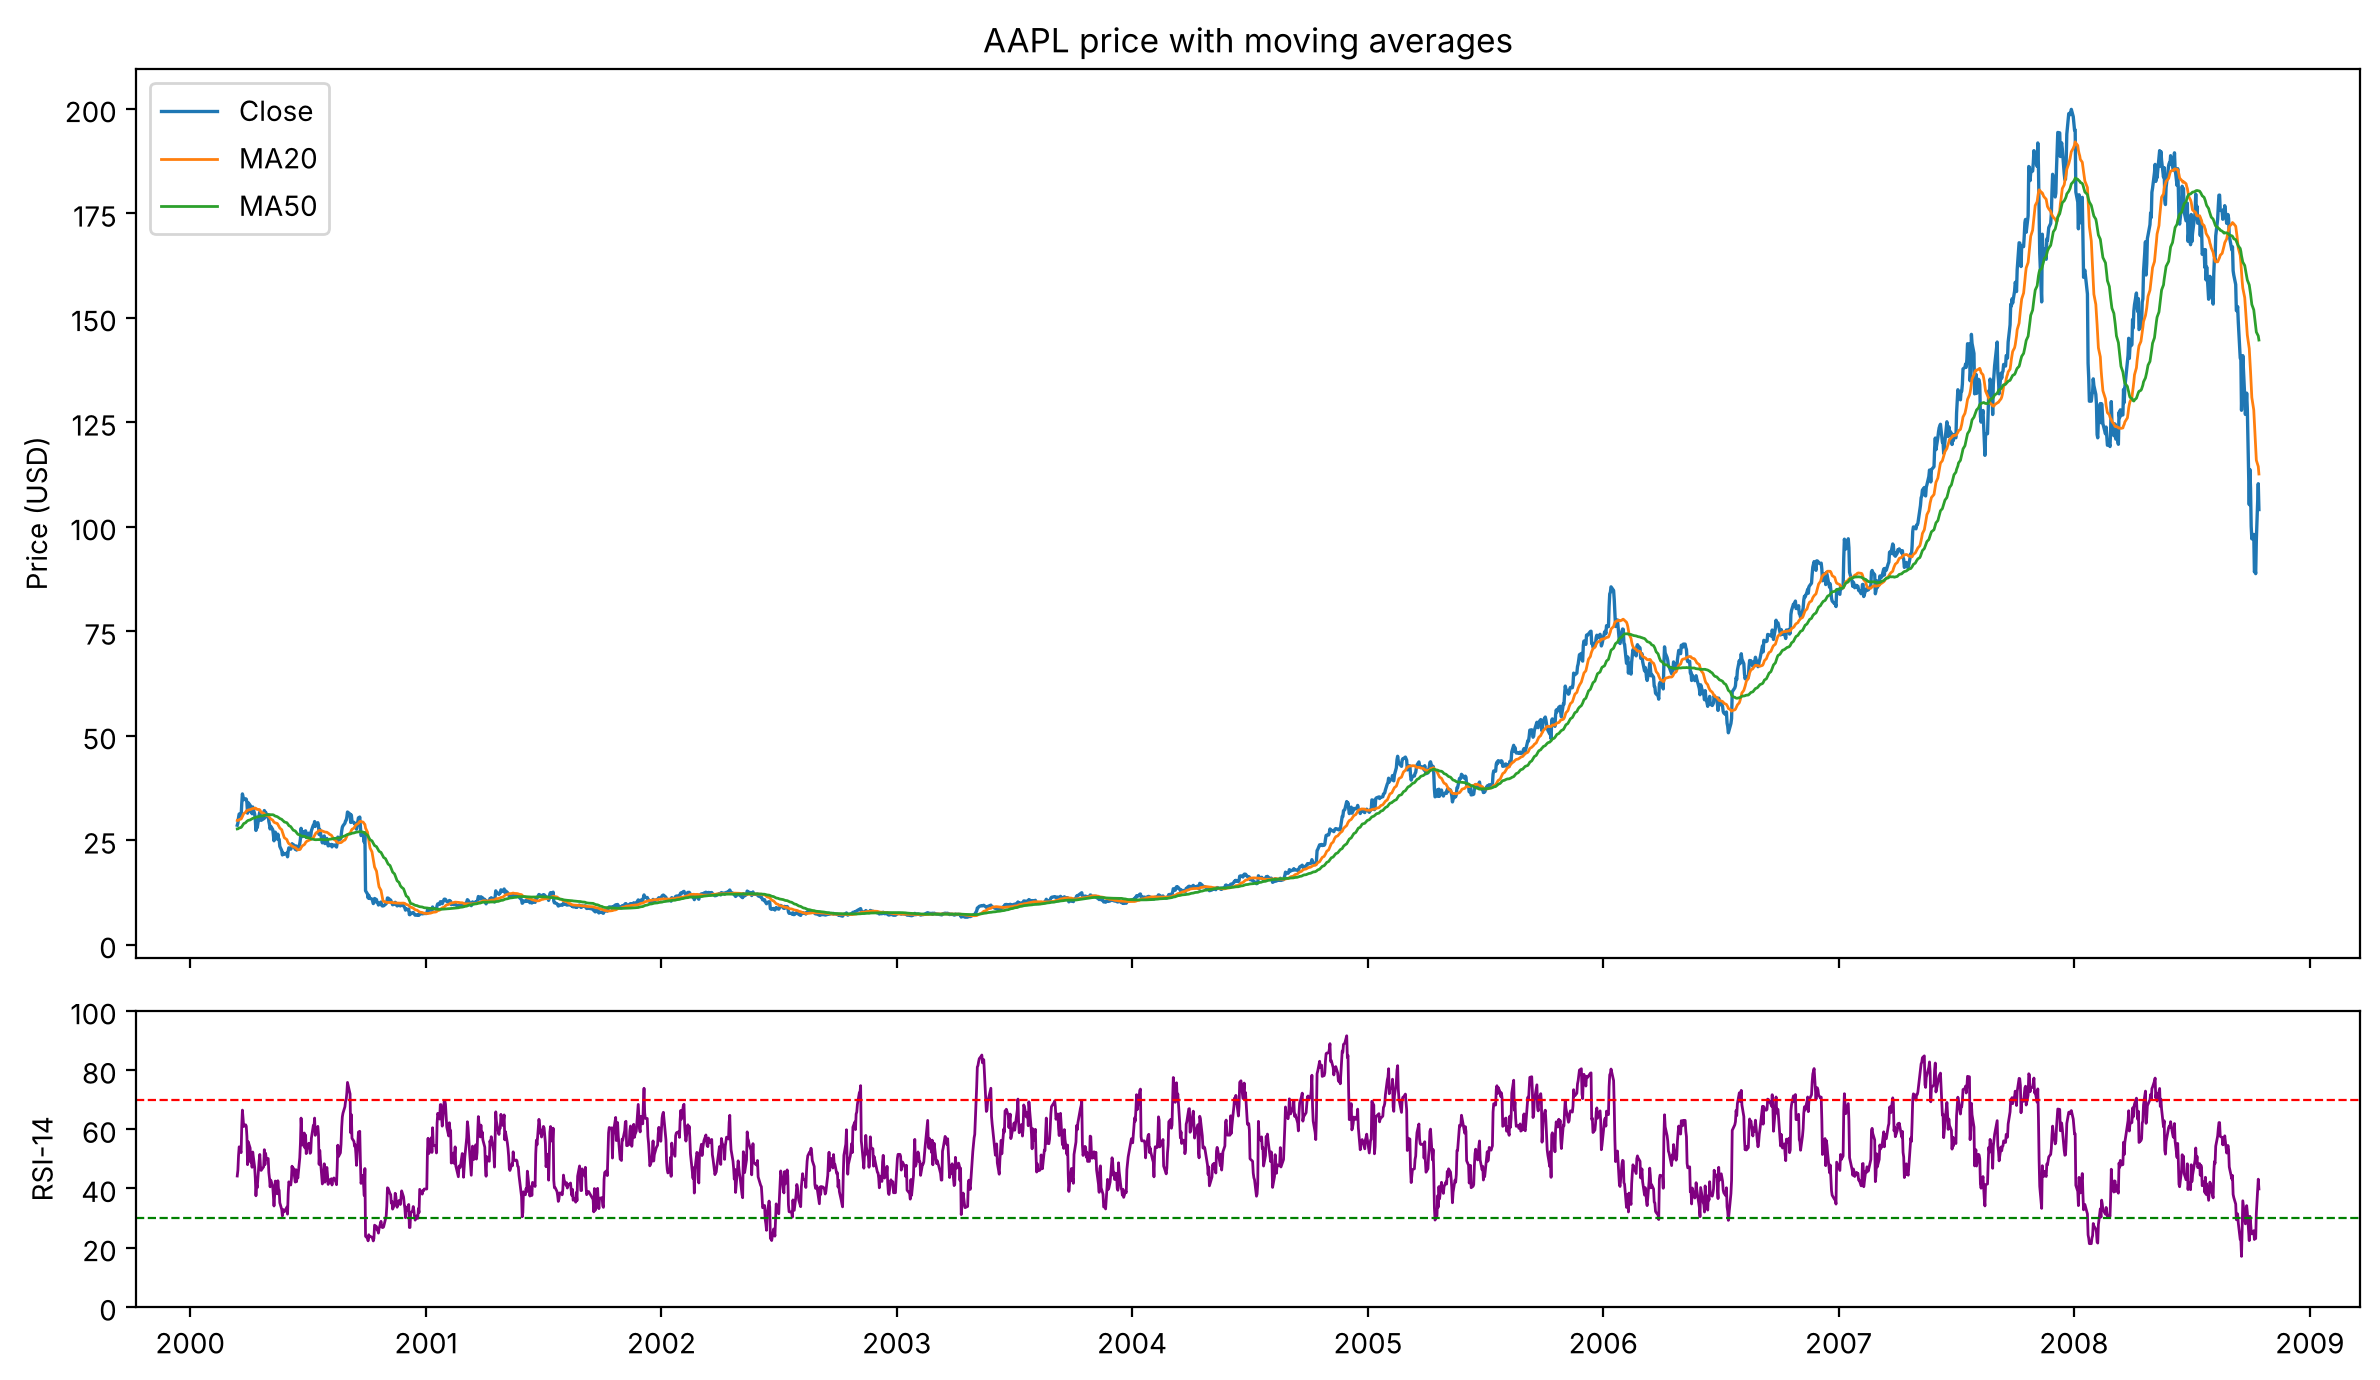

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(df.index, df["Close"], label="Close", lw=1.2)
ax1.plot(df.index, df["MA20"], label="MA20", lw=1)
ax1.plot(df.index, df["MA50"], label="MA50", lw=1)
ax1.set_title(f"{TICKER} price with moving averages"); ax1.set_ylabel("Price (USD)"); ax1.legend()
ax2.plot(df.index, df["RSI14"], color="purple", lw=1)
ax2.axhline(70, color="red", ls="--", lw=.8); ax2.axhline(30, color="green", ls="--", lw=.8)
ax2.set_ylabel("RSI-14"); ax2.set_ylim(0, 100)
plt.tight_layout(); plt.savefig(f"{OUT}/01_price_ma_rsi.png", dpi=150); plt.show()

## 4. Normalize and prepare sequences
The model predicts the **next-day log return**; the predicted price is rebuilt as `previous close x exp(predicted return)`. Features and target are standardized with scalers fit on the **training period only**, so no information from the test period leaks into training.

In [7]:
split = int(len(df) * TRAIN_FRAC)
train_df, test_df = df.iloc[:split], df.iloc[split:]

x_scaler = StandardScaler().fit(train_df[FEATURES])
y_scaler = StandardScaler().fit(train_df[["LogRet"]])

X_all = x_scaler.transform(df[FEATURES])
y_all = y_scaler.transform(df[["LogRet"]]).ravel()

def make_sequences(X, y, window, start, stop):
    # sample i: features of days [i-window, i) -> log return of day i
    xs, ys, idx = [], [], []
    for i in range(max(start, window), stop):
        xs.append(X[i-window:i]); ys.append(y[i]); idx.append(i)
    return np.array(xs), np.array(ys), np.array(idx)

X_tr, y_tr, i_tr = make_sequences(X_all, y_all, WINDOW, 0, split)
X_te, y_te, i_te = make_sequences(X_all, y_all, WINDOW, split, len(df))
print("train:", X_tr.shape, "| test:", X_te.shape)

train: (1668, 60, 4) | test: (432, 60, 4)


## 5. Build the LSTM model (Keras)

In [8]:
model = keras.Sequential([
    layers.Input(shape=(WINDOW, len(FEATURES))),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train and validate
Validation uses the **last 10% of the training sequences** (chronological, no shuffling). Early stopping restores the best weights.

In [9]:
cb = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
]
n_val = int(len(X_tr) * 0.10)
history = model.fit(
    X_tr[:-n_val], y_tr[:-n_val],
    validation_data=(X_tr[-n_val:], y_tr[-n_val:]),
    epochs=EPOCHS, batch_size=BATCH, shuffle=False, callbacks=cb, verbose=2)

Epoch 1/60


47/47 - 3s - 71ms/step - loss: 1.0496 - val_loss: 0.4208 - learning_rate: 0.0010


Epoch 2/60


47/47 - 2s - 48ms/step - loss: 1.0385 - val_loss: 0.4207 - learning_rate: 0.0010


Epoch 3/60


47/47 - 1s - 24ms/step - loss: 1.0359 - val_loss: 0.4202 - learning_rate: 0.0010


... (18 outputs left out)

Epoch 13/60


47/47 - 1s - 24ms/step - loss: 1.0232 - val_loss: 0.4253 - learning_rate: 5.0000e-04


Epoch 14/60


47/47 - 1s - 24ms/step - loss: 1.0294 - val_loss: 0.4235 - learning_rate: 5.0000e-04


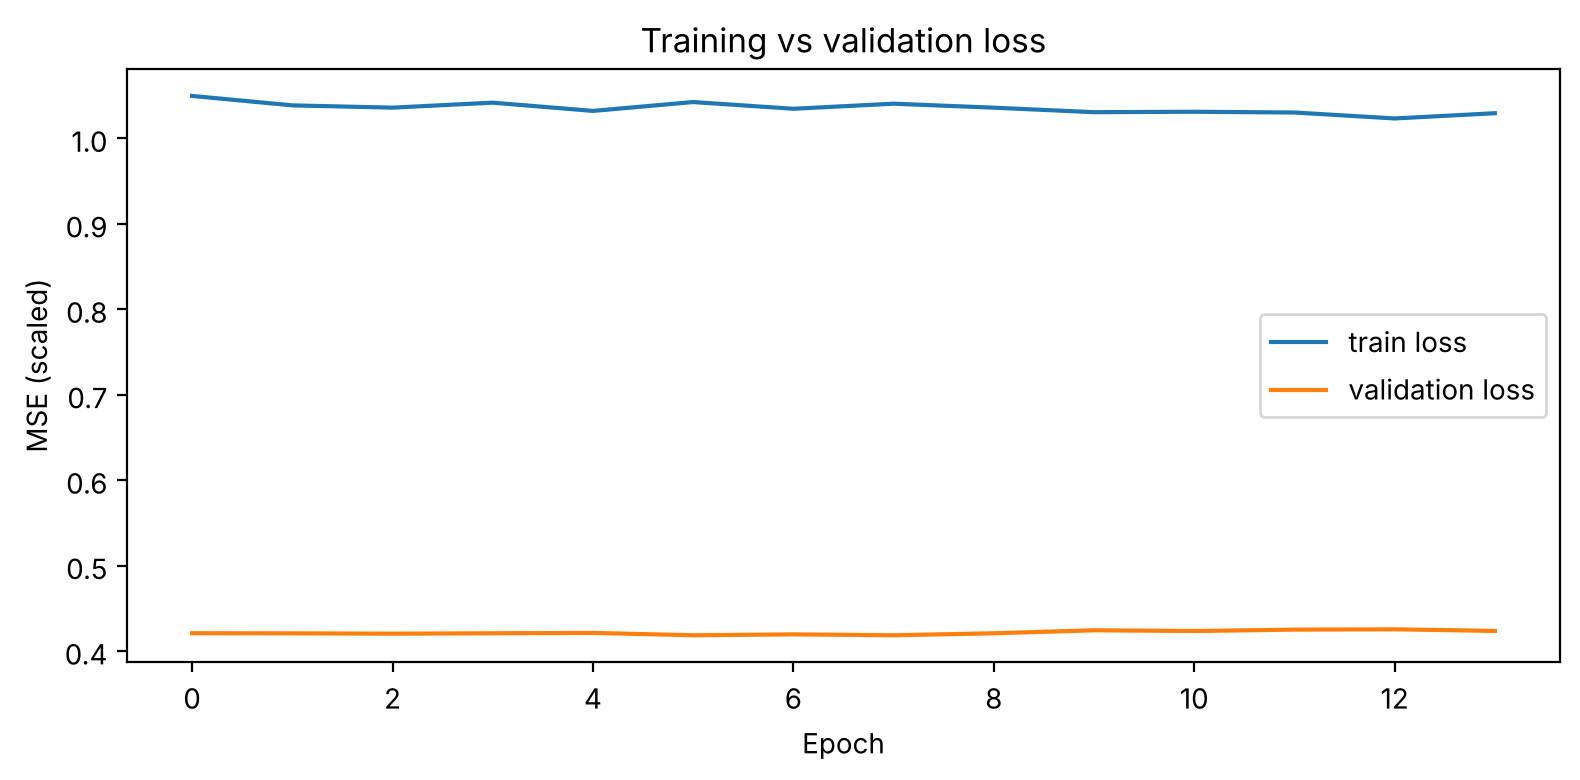

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE (scaled)"); plt.title("Training vs validation loss"); plt.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/02_loss_curve.png", dpi=150); plt.show()

## 7. Evaluate on the held-out test period

The test period is never used for training or early stopping. Next-day price forecasts are compared with a **naive baseline** (tomorrow's price = today's price). A next-day price model has to beat that baseline to be worth anything.

In [11]:
pred_ret = y_scaler.inverse_transform(model.predict(X_te, verbose=0)).ravel()
prev_close = df["Close"].values[i_te - 1]            # yesterday's close
pred = prev_close * np.exp(pred_ret)                  # LSTM price forecast
actual = df["Close"].values[i_te]

def metrics(a, p, prev=None):
    out = dict(RMSE=float(np.sqrt(np.mean((a - p) ** 2))),
               MAE=float(np.mean(np.abs(a - p))),
               MAPE_pct=float(np.mean(np.abs((a - p) / a)) * 100))
    if prev is not None:   # direction is only defined for a model that predicts a move
        out["Directional_acc_pct"] = float(np.mean(np.sign(a - prev) == np.sign(p - prev)) * 100)
    return out

res = {"LSTM": metrics(actual, pred, prev_close),
       "Naive (yesterday's close)": metrics(actual, prev_close)}
res["Context: share of up-days in test period (%)"] = {"Directional_acc_pct": float(np.mean(actual > prev_close) * 100)}
res_df = pd.DataFrame(res).T.round(3)
res_df

,RMSE,MAE,MAPE_pct,Directional_acc_pct
LSTM,4.140,2.990,2.105,55.556
Naive (yesterday's close),4.141,3.001,2.112,NaN
Context: share of up-days in test period (%),NaN,NaN,NaN,53.704


## 8. Plot predictions vs actual

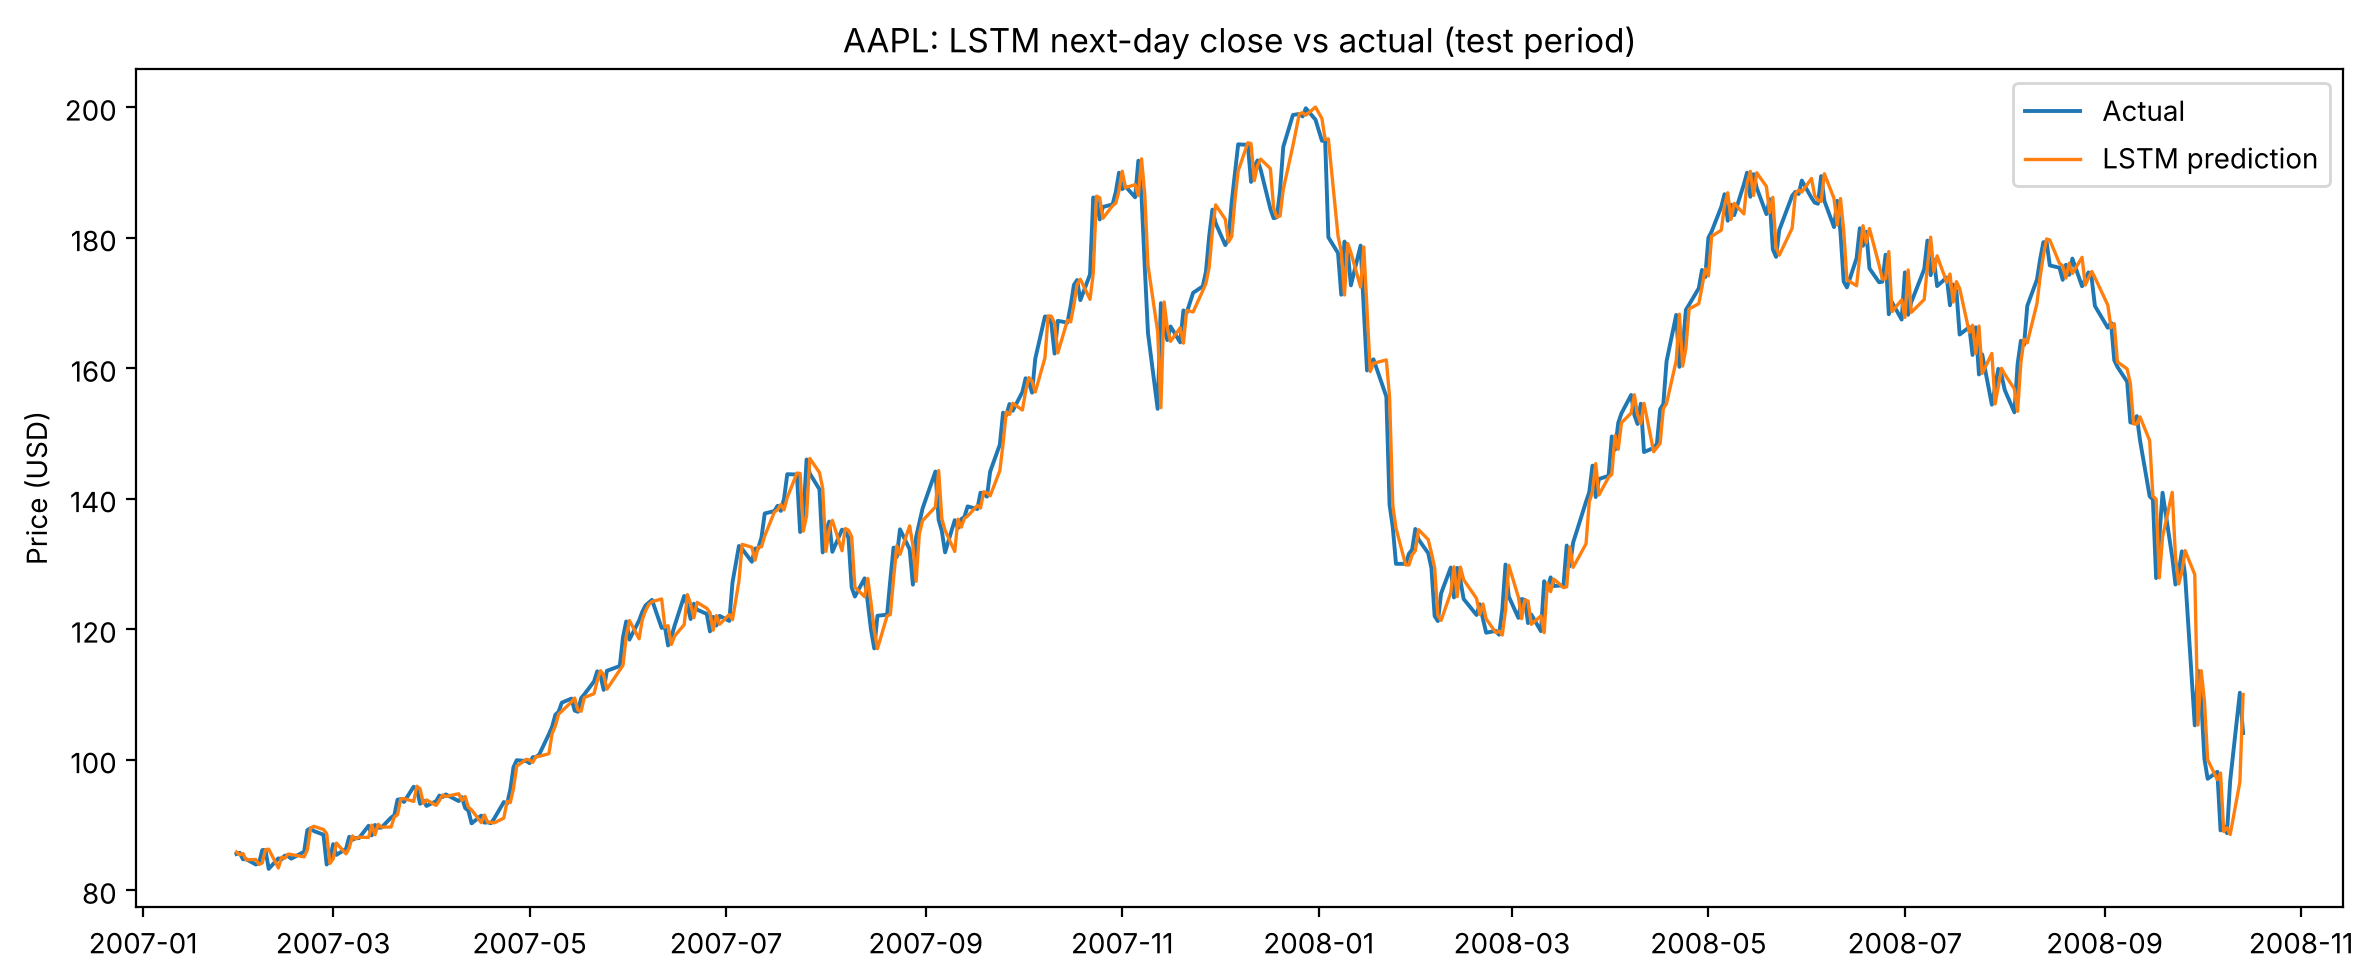

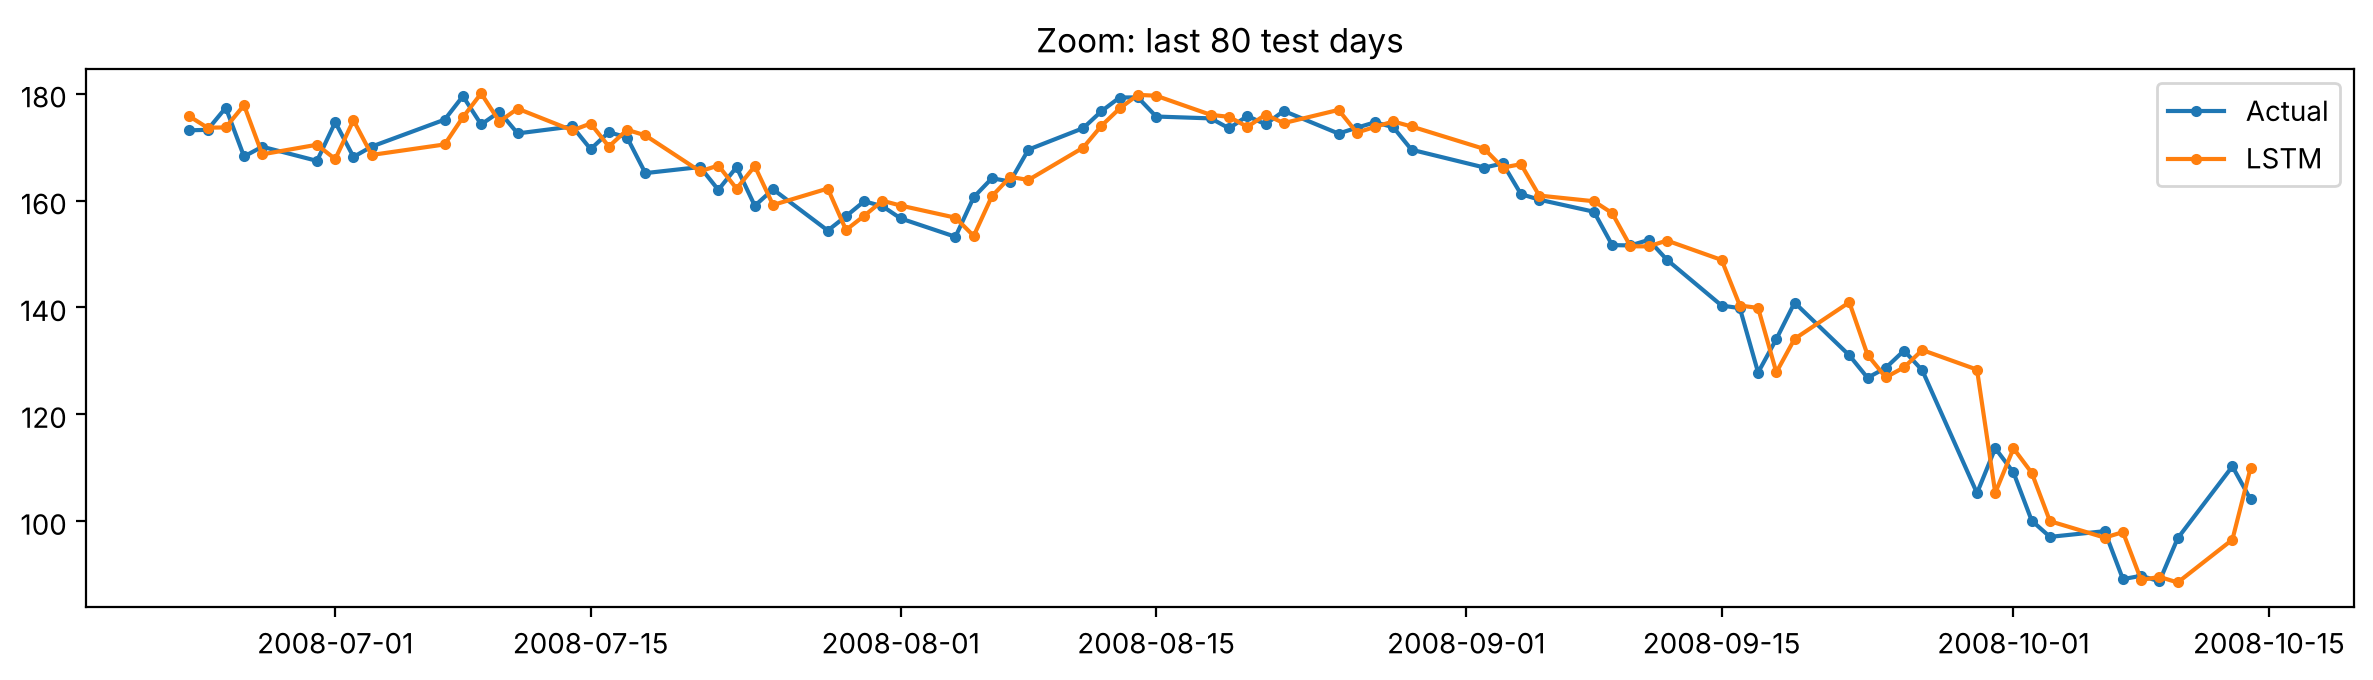

In [12]:
dates = df.index[i_te]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates, actual, label="Actual", lw=1.4)
ax.plot(dates, pred, label="LSTM prediction", lw=1.2)
ax.set_title(f"{TICKER}: LSTM next-day close vs actual (test period)")
ax.set_ylabel("Price (USD)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/03_pred_vs_actual.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(dates[-80:], actual[-80:], label="Actual", marker="o", ms=3)
ax.plot(dates[-80:], pred[-80:], label="LSTM", marker="o", ms=3)
ax.set_title("Zoom: last 80 test days"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/04_pred_vs_actual_zoom.png", dpi=150); plt.show()

## 9. Next-day forecast and save model weights

In [13]:
last_window = X_all[-WINDOW:].reshape(1, WINDOW, len(FEATURES))
next_ret = float(y_scaler.inverse_transform(model.predict(last_window, verbose=0))[0, 0])
next_close = float(df["Close"].iloc[-1] * np.exp(next_ret))
print(f"Last close ({df.index[-1].date()}): {df['Close'].iloc[-1]:.2f}  ->  next-day forecast: {next_close:.2f}")

model.save(f"{MODELS}/lstm_stock.keras")
model.save_weights(f"{MODELS}/lstm_stock.weights.h5")
joblib.dump({"x_scaler": x_scaler, "y_scaler": y_scaler}, f"{MODELS}/scalers.joblib")
meta = dict(ticker=TICKER, data_source=SOURCE, window=WINDOW, features=FEATURES,
            rows=len(df), start=str(df.index.min().date()), end=str(df.index.max().date()),
            epochs_run=len(history.history["loss"]), metrics=res, next_day_forecast=next_close)
json.dump(meta, open(f"{OUT}/results.json", "w"), indent=2)
print(json.dumps(meta, indent=2))

Last close (2008-10-14): 104.08  ->  next-day forecast: 103.91
{
  "ticker": "AAPL",
  "data_source": "Backup public AAPL dataset (2000-2008)",
  "window": 60,
  "features": [
    "LogRet",
    "MA20_dev",
    "MA50_dev",
    "RSI14_n"
  ],
  "rows": 2160,
  "start": "2000-03-14",
  "end": "2008-10-14",
  "epochs_run": 14,
  "metrics": {
    "LSTM": {
      "RMSE": 4.139941396298712,
      "MAE": 2.9904216345675576,
      "MAPE_pct": 2.1049034534518114,
      "Directional_acc_pct": 55.55555555555556
    },
    "Naive (yesterday's close)": {
      "RMSE": 4.141012970992234,
      "MAE": 3.0011574074074083,
      "MAPE_pct": 2.1121444831066105
    },
    "Context: share of up-days in test period (%)": {
      "Directional_acc_pct": 53.70370370370371
    }
  },
  "next_day_forecast": 103.90580924321881
}


## 10. Notes and limitations
* Markets are close to a random walk, so a next-day *price* model that mostly echoes yesterday's close can look accurate on RMSE/MAPE without being useful. Compare against the naive baseline and the directional accuracy (and the share of up-days), as in section 7.
* Predicting raw price levels fails when the price leaves the training range (the LSTM flat-lines), which is why this notebook models returns and rebuilds the price.
* This is an educational project, not trading advice.

In [14]:
# Bundle everything for GitHub and download it (Colab)
import shutil
for d in (DATA, MODELS, OUT):
    print(d, "->", sorted(os.listdir(d)))
shutil.make_archive("lstm_outputs", "zip", root_dir=".", base_dir=OUT)
shutil.make_archive("lstm_models", "zip", root_dir=".", base_dir=MODELS)
shutil.make_archive("lstm_data", "zip", root_dir=".", base_dir=DATA)
try:
    from google.colab import files
    for z in ("lstm_data.zip", "lstm_models.zip", "lstm_outputs.zip"):
        files.download(z)
except ImportError:
    print("Not in Colab: zips are in the working folder.")

data -> ['AAPL_prices_with_indicators.csv', 'aapl_fallback.csv']
models -> ['lstm_stock.keras', 'lstm_stock.weights.h5', 'scalers.joblib']
outputs -> ['01_price_ma_rsi.png', '02_loss_curve.png', '03_pred_vs_actual.png', '04_pred_vs_actual_zoom.png', 'results.json']
Not in Colab: zips are in the working folder.
